# Hyperliquid Trader Behavior × Market Sentiment (Fear/Greed) Analysis

**Objective:** Analyze how Bitcoin market sentiment relates to trader behavior and performance on Hyperliquid — uncovering patterns that inform smarter trading strategies.

---
## Notebook Structure
- **Part A** — Data Preparation & EDA
- **Part B** — Sentiment vs Performance & Behavior Analysis
- **Part C** — Trader Segmentation & Actionable Insights


## 0. Setup & Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from scipy import stats
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# ── Aesthetics ──────────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.facecolor': '#0f1117',
    'axes.facecolor':   '#1a1d2e',
    'axes.edgecolor':   '#3a3d52',
    'axes.labelcolor':  '#e0e0e0',
    'xtick.color':      '#a0a0b0',
    'ytick.color':      '#a0a0b0',
    'text.color':       '#e0e0e0',
    'grid.color':       '#2a2d3e',
    'grid.alpha':       0.5,
    'font.family':      'DejaVu Sans',
    'font.size':        11,
    'axes.titlesize':   14,
    'axes.titleweight': 'bold',
    'figure.dpi':       130,
})

# Sentiment color palette
SENT_COLORS = {
    'Extreme Fear': '#e74c3c',
    'Fear':         '#e67e22',
    'Neutral':      '#95a5a6',
    'Greed':        '#2ecc71',
    'Extreme Greed':'#27ae60',
}

CHARTS_DIR = Path('../charts')
CHARTS_DIR.mkdir(exist_ok=True)

def save(name):
    plt.savefig(CHARTS_DIR / f'{name}.png', bbox_inches='tight', facecolor=plt.rcParams['figure.facecolor'])
    plt.show()
    print(f'  ✔ saved → charts/{name}.png')

print('✅ Setup complete')

✅ Setup complete


---
# Part A — Data Preparation

## A1. Load Datasets

In [3]:
# ── Load Fear/Greed Index ────────────────────────────────────────────────────
fg = pd.read_csv('../data/fear_greed_index.csv')
print('=== Fear/Greed Index ===')
print(f'  Rows: {len(fg):,}   Columns: {fg.shape[1]}')
print(f'  Columns: {list(fg.columns)}')
print(f'  Missing values:\n{fg.isnull().sum()}')
print(f'  Duplicates: {fg.duplicated().sum()}')
fg.head(3)

=== Fear/Greed Index ===
  Rows: 2,644   Columns: 4
  Columns: ['timestamp', 'value', 'classification', 'date']
  Missing values:
timestamp         0
value             0
classification    0
date              0
dtype: int64
  Duplicates: 0


,timestamp,value,classification,date
0,1517463000,30,Fear,2018-02-01
1,1517549400,15,Extreme Fear,2018-02-02
2,1517635800,40,Fear,2018-02-03


In [4]:
# ── Load Hyperliquid Trade History ───────────────────────────────────────────
hl = pd.read_csv('../data/historical_data.csv')
print('=== Hyperliquid Historical Trades ===')
print(f'  Rows: {len(hl):,}   Columns: {hl.shape[1]}')
print(f'  Columns: {list(hl.columns)}')
print(f'  Missing values:\n{hl.isnull().sum()}')
print(f'  Duplicates: {hl.duplicated().sum()}')
hl.head(3)

=== Hyperliquid Historical Trades ===
  Rows: 211,224   Columns: 16
  Columns: ['Account', 'Coin', 'Execution Price', 'Size Tokens', 'Size USD', 'Side', 'Timestamp IST', 'Start Position', 'Direction', 'Closed PnL', 'Transaction Hash', 'Order ID', 'Crossed', 'Fee', 'Trade ID', 'Timestamp']
  Missing values:
Account             0
Coin                0
Execution Price     0
Size Tokens         0
Size USD            0
Side                0
Timestamp IST       0
Start Position      0
Direction           0
Closed PnL          0
Transaction Hash    0
Order ID            0
Crossed             0
Fee                 0
Trade ID            0
Timestamp           0
dtype: int64
  Duplicates: 0


,Account,Coin,Execution Price,Size Tokens,Size USD,Side,Timestamp IST,Start Position,Direction,Closed PnL,Transaction Hash,Order ID,Crossed,Fee,Trade ID,Timestamp
0,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9769,986.87,7872.16,BUY,02-12-2024 22:50,0.000000,Buy,0.0,0xec09451986a1874e3a980418412fcd0201f500c95bac...,52017706630,True,0.345404,8.950000e+14,1.730000e+12
1,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9800,16.00,127.68,BUY,02-12-2024 22:50,986.524596,Buy,0.0,0xec09451986a1874e3a980418412fcd0201f500c95bac...,52017706630,True,0.005600,4.430000e+14,1.730000e+12
2,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9855,144.09,1150.63,BUY,02-12-2024 22:50,1002.518996,Buy,0.0,0xec09451986a1874e3a980418412fcd0201f500c95bac...,52017706630,True,0.050431,6.600000e+14,1.730000e+12


## A2. Timestamp Alignment

In [5]:
# ── Fear/Greed: parse date ───────────────────────────────────────────────────
fg['date'] = pd.to_datetime(fg['date'])
fg = fg.drop_duplicates(subset='date').sort_values('date').reset_index(drop=True)

# Ordinal encoding for sentiment strength
SENT_ORDER = ['Extreme Fear', 'Fear', 'Neutral', 'Greed', 'Extreme Greed']
fg['sentiment_score'] = fg['classification'].map(
    {s: i for i, s in enumerate(SENT_ORDER)}
)

# Binary: Fear vs Greed
fg['sentiment_binary'] = fg['classification'].apply(
    lambda x: 'Fear' if 'Fear' in x else ('Greed' if 'Greed' in x else 'Neutral')
)

print(fg['classification'].value_counts())
fg.tail(3)

classification
Fear             781
Greed            633
Extreme Fear     508
Neutral          396
Extreme Greed    326
Name: count, dtype: int64


,timestamp,value,classification,date,sentiment_score,sentiment_binary
2641,1745991000,56,Greed,2025-04-30,3,Greed
2642,1746077400,53,Neutral,2025-05-01,2,Neutral
2643,1746163800,67,Greed,2025-05-02,3,Greed


In [6]:
# ── Hyperliquid: parse timestamp ─────────────────────────────────────────────
# 'Timestamp IST' is the human-readable column; 'Timestamp' is epoch ms
hl['datetime'] = pd.to_datetime(hl['Timestamp IST'], dayfirst=True, errors='coerce')

# Fallback: epoch milliseconds column
mask = hl['datetime'].isna()
if mask.any():
    hl.loc[mask, 'datetime'] = pd.to_datetime(hl.loc[mask, 'Timestamp'], unit='ms', errors='coerce')

hl = hl.dropna(subset=['datetime'])
hl['date'] = hl['datetime'].dt.normalize()

# Clean numeric columns
for col in ['Closed PnL', 'Size USD', 'Size Tokens', 'Execution Price', 'Fee']:
    hl[col] = pd.to_numeric(hl[col], errors='coerce').fillna(0)

# Direction flag
hl['is_long'] = hl['Side'].str.upper().eq('BUY').astype(int)

print(f'Trade date range: {hl["date"].min().date()} → {hl["date"].max().date()}')
print(f'Unique accounts: {hl["Account"].nunique():,}')
hl.head(3)

Trade date range: 2023-05-01 → 2025-05-01
Unique accounts: 32


,Account,Coin,Execution Price,Size Tokens,Size USD,Side,Timestamp IST,Start Position,Direction,Closed PnL,Transaction Hash,Order ID,Crossed,Fee,Trade ID,Timestamp,datetime,date,is_long
0,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9769,986.87,7872.16,BUY,02-12-2024 22:50,0.000000,Buy,0.0,0xec09451986a1874e3a980418412fcd0201f500c95bac...,52017706630,True,0.345404,8.950000e+14,1.730000e+12,2024-12-02 22:50:00,2024-12-02,1
1,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9800,16.00,127.68,BUY,02-12-2024 22:50,986.524596,Buy,0.0,0xec09451986a1874e3a980418412fcd0201f500c95bac...,52017706630,True,0.005600,4.430000e+14,1.730000e+12,2024-12-02 22:50:00,2024-12-02,1
2,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9855,144.09,1150.63,BUY,02-12-2024 22:50,1002.518996,Buy,0.0,0xec09451986a1874e3a980418412fcd0201f500c95bac...,52017706630,True,0.050431,6.600000e+14,1.730000e+12,2024-12-02 22:50:00,2024-12-02,1


## A3. Build Daily Metrics per Trader

In [7]:
# ── Per-trade win flag ───────────────────────────────────────────────────────
hl['is_win'] = (hl['Closed PnL'] > 0).astype(int)
hl['is_close'] = (hl['Closed PnL'] != 0).astype(int)  # only closing trades have PnL

# ── Daily aggregation per Account ───────────────────────────────────────────
daily = (
    hl.groupby(['Account', 'date'])
    .agg(
        daily_pnl        = ('Closed PnL',   'sum'),
        trade_count      = ('Trade ID',      'count'),
        avg_size_usd     = ('Size USD',      'mean'),
        total_volume_usd = ('Size USD',      'sum'),
        wins             = ('is_win',        'sum'),
        closes           = ('is_close',      'sum'),
        long_trades      = ('is_long',       'sum'),
        total_fee        = ('Fee',           'sum'),
    )
    .reset_index()
)

daily['win_rate']      = np.where(daily['closes'] > 0, daily['wins'] / daily['closes'], np.nan)
daily['long_ratio']    = daily['long_trades'] / daily['trade_count']
daily['pnl_positive']  = (daily['daily_pnl'] > 0).astype(int)

print(f'Daily trader-day rows: {len(daily):,}')
daily.describe().round(2)

Daily trader-day rows: 2,341


,date,daily_pnl,trade_count,avg_size_usd,total_volume_usd,wins,closes,long_trades,total_fee,win_rate,long_ratio,pnl_positive
count,2341,2341.00,2341.00,2341.00,2341.00,2341.00,2341.00,2341.00,2341.00,1693.00,2341.00,2341.00
mean,2024-12-22 00:49:49.491670016,4398.53,90.23,6989.52,508837.01,37.11,44.60,43.87,105.02,0.85,0.49,0.63
min,2023-05-01 00:00:00,-358963.14,1.00,0.00,0.00,0.00,0.00,0.00,-4.85,0.00,0.00,0.00
25%,2024-11-28 00:00:00,0.00,9.00,695.25,15764.01,0.00,0.00,1.00,2.98,0.86,0.14,0.00
50%,2025-01-28 00:00:00,207.98,29.00,1914.00,69357.39,7.00,9.00,11.00,13.71,1.00,0.49,1.00
75%,2025-03-18 00:00:00,1842.84,80.00,7051.01,250781.18,31.00,38.00,38.00,55.31,1.00,0.83,1.00
max,2025-05-01 00:00:00,533974.66,4083.00,844654.19,51250451.44,1824.00,1824.00,2675.00,10554.75,1.00,1.00,1.00
std,NaN,28415.94,214.61,21538.69,2413745.03,102.57,120.09,121.49,461.39,0.29,0.36,0.48


In [8]:
# ── Merge with sentiment ─────────────────────────────────────────────────────
daily = daily.merge(fg[['date','value','classification','sentiment_binary','sentiment_score']],
                    on='date', how='left')

matched = daily['classification'].notna().sum()
print(f'Trader-days with sentiment data: {matched:,} / {len(daily):,}  ({matched/len(daily)*100:.1f}%)')

daily_sent = daily.dropna(subset=['classification']).copy()
print(f'\nSentiment distribution in trader-days:')
print(daily_sent['classification'].value_counts())

Trader-days with sentiment data: 2,340 / 2,341  (100.0%)

Sentiment distribution in trader-days:
classification
Greed            648
Fear             630
Extreme Greed    526
Neutral          376
Extreme Fear     160
Name: count, dtype: int64


In [9]:
# ── Global per-trader summary (for segmentation) ────────────────────────────
trader_stats = (
    daily_sent.groupby('Account')
    .agg(
        total_pnl      = ('daily_pnl',       'sum'),
        avg_daily_pnl  = ('daily_pnl',       'mean'),
        pnl_std        = ('daily_pnl',       'std'),
        total_trades   = ('trade_count',     'sum'),
        trading_days   = ('date',            'nunique'),
        avg_size_usd   = ('avg_size_usd',    'mean'),
        mean_win_rate  = ('win_rate',        'mean'),
        mean_long_ratio= ('long_ratio',      'mean'),
    )
    .reset_index()
)
trader_stats['avg_trades_per_day'] = trader_stats['total_trades'] / trader_stats['trading_days']
trader_stats['sharpe_proxy']       = trader_stats['avg_daily_pnl'] / (trader_stats['pnl_std'] + 1e-9)

print(f'Unique traders analyzed: {len(trader_stats):,}')
trader_stats.describe().round(2)

Unique traders analyzed: 32


,total_pnl,avg_daily_pnl,pnl_std,total_trades,trading_days,avg_size_usd,mean_win_rate,mean_long_ratio,avg_trades_per_day,sharpe_proxy
count,32.00,32.00,32.00,32.00,32.00,32.00,32.00,32.00,32.00,32.00
mean,320452.72,7127.04,23121.08,6600.56,73.12,8812.49,0.84,0.48,112.59,0.30
std,494659.65,13530.88,30515.25,8250.50,72.73,9180.18,0.12,0.13,147.52,0.21
min,-167621.12,-5869.68,873.41,332.00,12.00,484.84,0.53,0.19,11.27,-0.18
25%,46893.24,792.68,4841.40,1377.25,27.50,2396.29,0.77,0.41,33.22,0.19
50%,117655.08,2141.13,11240.00,3699.00,46.50,4608.20,0.86,0.48,59.56,0.29
75%,388457.02,7367.27,30886.36,8862.50,74.75,11413.21,0.92,0.53,138.67,0.47
max,2143382.60,66676.24,150401.80,40184.00,321.00,33569.10,1.00,0.76,756.86,0.66


---
# Part B — Sentiment vs Performance & Behavior

## B1. Does performance differ between Fear vs Greed days?

In [11]:
# ── Aggregate daily metrics by sentiment class ───────────────────────────────
sent_perf = (
    daily_sent.groupby('classification')
    .agg(
        avg_pnl      = ('daily_pnl',  'mean'),
        median_pnl   = ('daily_pnl',  'median'),
        pnl_std      = ('daily_pnl',  'std'),
        win_rate     = ('pnl_positive','mean'),
        avg_trades   = ('trade_count', 'mean'),
        avg_vol      = ('total_volume_usd','mean'),
        n_obs        = ('daily_pnl',   'count'),
    )
    .reindex(SENT_ORDER)
    .dropna(how='all')
)

print('Performance by sentiment class:')
print(sent_perf.round(4).to_string())

Performance by sentiment class:
                  avg_pnl  median_pnl     pnl_std  win_rate  avg_trades      avg_vol  n_obs
classification                                                                             
Extreme Fear    4619.4391    218.3774  29534.8392    0.6000    133.7500  715526.6340    160
Fear            5328.8182    107.8925  31659.7715    0.6048     98.1540  767182.2060    630
Neutral         3438.6188    167.5517  17447.8636    0.6223    100.2287  479367.1890    376
Greed           3318.1007    158.2149  30599.0402    0.6111     77.6281  445343.3560    648
Extreme Greed   5161.9226    418.3199  27496.8638    0.6825     76.0304  236625.7882    526


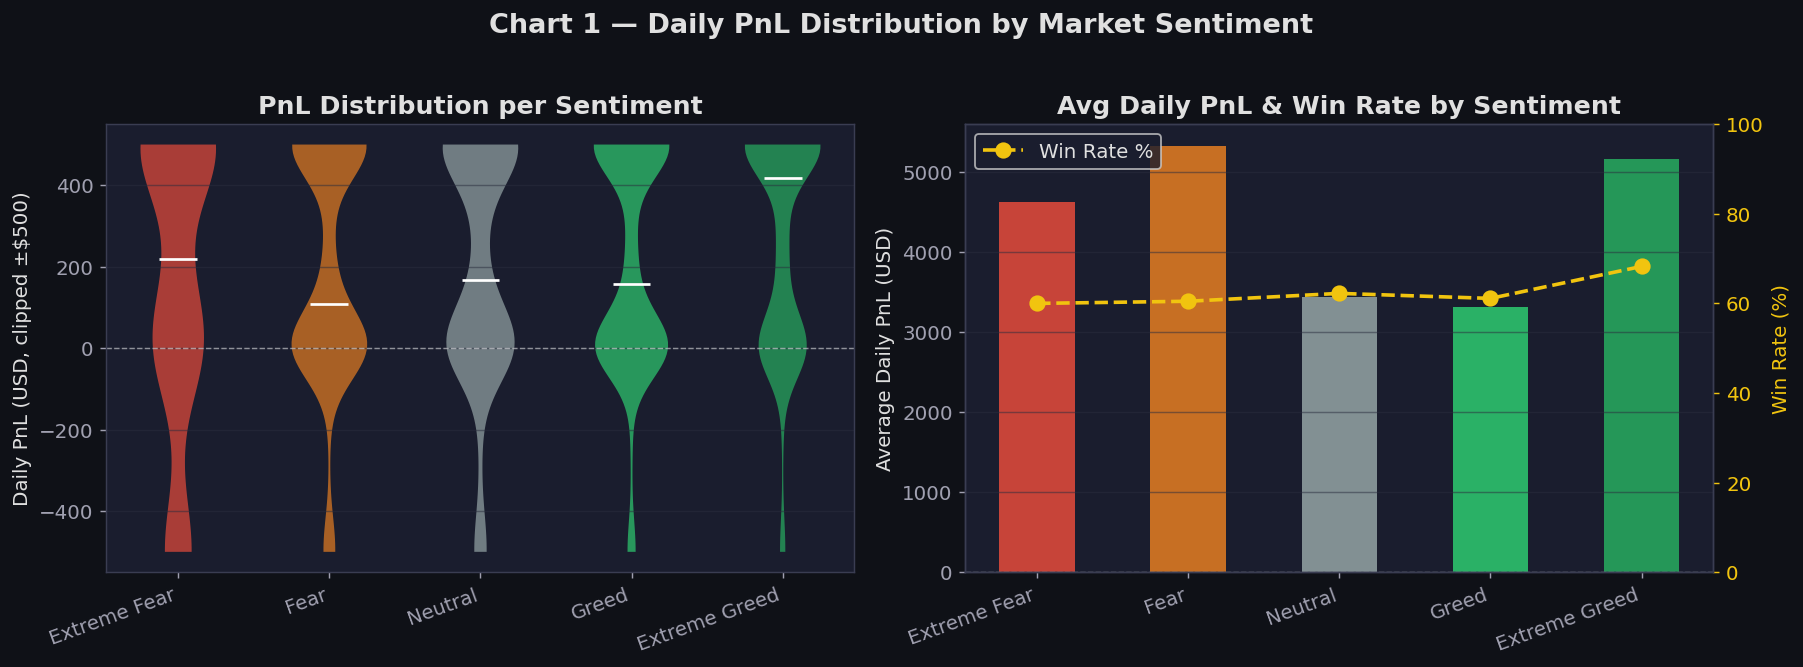

  ✔ saved → charts/chart1_pnl_by_sentiment.png


In [25]:
# ── Chart 1: PnL distribution by sentiment ──────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Chart 1 — Daily PnL Distribution by Market Sentiment', fontsize=15, fontweight='bold', y=1.02)

# Violin plot
ax = axes[0]
order = [s for s in SENT_ORDER if s in daily_sent['classification'].unique()]
palette = {s: SENT_COLORS[s] for s in order}

data_by_sent = [daily_sent.loc[daily_sent['classification'] == s, 'daily_pnl'].clip(-500, 500)
                for s in order]

parts = ax.violinplot(data_by_sent, positions=range(len(order)), showmedians=True, showextrema=False)
for i, (pc, s) in enumerate(zip(parts['bodies'], order)):
    pc.set_facecolor(SENT_COLORS[s])
    pc.set_alpha(0.7)
parts['cmedians'].set_color('white')

ax.set_xticks(range(len(order)))
ax.set_xticklabels(order, rotation=20, ha='right')
ax.set_ylabel('Daily PnL (USD, clipped ±$500)')
ax.set_title('PnL Distribution per Sentiment')
ax.axhline(0, color='white', lw=0.8, ls='--', alpha=0.5)
ax.grid(axis='y')

# Bar chart: avg PnL & win rate
ax2 = axes[1]
x = np.arange(len(order))
bars = ax2.bar(x, sent_perf.loc[order, 'avg_pnl'],
               color=[SENT_COLORS[s] for s in order], width=0.5, alpha=0.85)
ax2.set_xticks(x)
ax2.set_xticklabels(order, rotation=20, ha='right')
ax2.set_ylabel('Average Daily PnL (USD)')
ax2.set_title('Avg Daily PnL & Win Rate by Sentiment')
ax2.axhline(0, color='white', lw=0.8, ls='--', alpha=0.5)
ax2.grid(axis='y')

# Overlay win rate as text
ax2b = ax2.twinx()
ax2b.plot(x, sent_perf.loc[order, 'win_rate'] * 100, 'o--', color='#f1c40f', lw=2, ms=8, label='Win Rate %')
ax2b.set_ylabel('Win Rate (%)', color='#f1c40f')
ax2b.tick_params(axis='y', colors='#f1c40f')
ax2b.set_ylim(0, 100)
ax2b.legend(loc='upper left')

plt.tight_layout()
save('chart1_pnl_by_sentiment')

In [13]:
# ── Statistical test: Fear vs Greed PnL ──────────────────────────────────────
fear_pnl  = daily_sent.loc[daily_sent['sentiment_binary'] == 'Fear',  'daily_pnl']
greed_pnl = daily_sent.loc[daily_sent['sentiment_binary'] == 'Greed', 'daily_pnl']

t_stat, p_val = stats.mannwhitneyu(fear_pnl, greed_pnl, alternative='two-sided')
print(f'Mann-Whitney U test (Fear PnL vs Greed PnL)')
print(f'  Fear  — median: ${fear_pnl.median():.2f}, mean: ${fear_pnl.mean():.2f}, n={len(fear_pnl):,}')
print(f'  Greed — median: ${greed_pnl.median():.2f}, mean: ${greed_pnl.mean():.2f}, n={len(greed_pnl):,}')
print(f'  U={t_stat:.0f}, p={p_val:.4f}  → {"SIGNIFICANT" if p_val < 0.05 else "NOT significant"} at 5%')

Mann-Whitney U test (Fear PnL vs Greed PnL)
  Fear  — median: $122.74, mean: $5185.15, n=790
  Greed — median: $265.25, mean: $4144.21, n=1,174
  U=440966, p=0.0618  → NOT significant at 5%


## B2. Do traders change behavior based on sentiment?

In [14]:
# ── Behavior metrics by sentiment ────────────────────────────────────────────
behavior = (
    daily_sent.groupby('classification')
    .agg(
        avg_trades       = ('trade_count',       'mean'),
        avg_volume       = ('total_volume_usd',  'mean'),
        avg_size         = ('avg_size_usd',      'mean'),
        avg_long_ratio   = ('long_ratio',        'mean'),
    )
    .reindex(order)
    .dropna(how='all')
)
print('Behavior metrics by sentiment:')
print(behavior.round(3).to_string())

Behavior metrics by sentiment:
                avg_trades  avg_volume  avg_size  avg_long_ratio
classification                                                  
Extreme Fear       133.750  715526.634  6773.464           0.532
Fear                98.154  767182.206  8975.929           0.519
Neutral            100.229  479367.189  6963.695           0.472
Greed               77.628  445343.356  6427.867           0.472
Extreme Greed       76.030  236625.788  5371.637           0.473


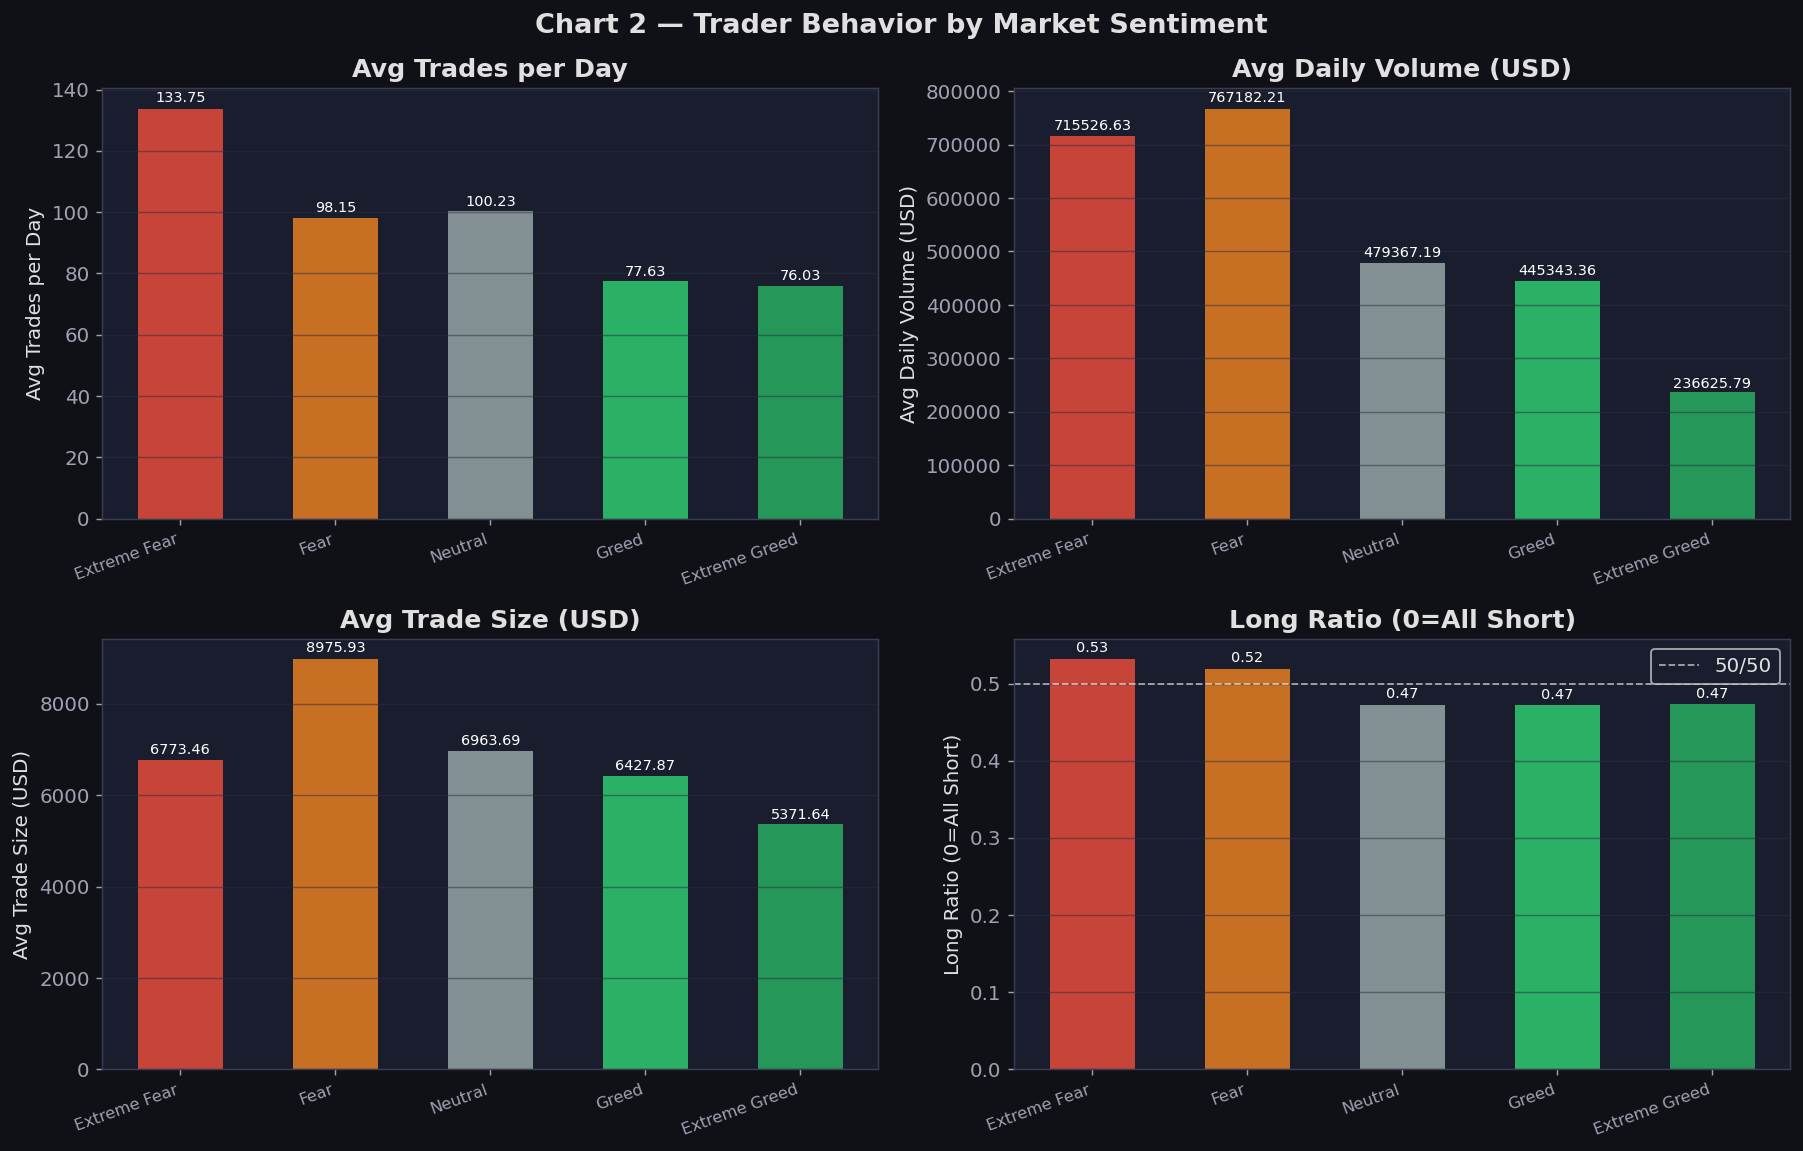

  ✔ saved → charts/chart2_behavior_by_sentiment.png


In [15]:
# ── Chart 2: Behavioral shifts across sentiment ──────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle('Chart 2 — Trader Behavior by Market Sentiment', fontsize=15, fontweight='bold')

metrics = [
    ('avg_trades',     'Avg Trades per Day',        axes[0,0]),
    ('avg_volume',     'Avg Daily Volume (USD)',     axes[0,1]),
    ('avg_size',       'Avg Trade Size (USD)',       axes[1,0]),
    ('avg_long_ratio', 'Long Ratio (0=All Short)',   axes[1,1]),
]

for col, ylabel, ax in metrics:
    vals = behavior[col].values
    colors = [SENT_COLORS[s] for s in behavior.index]
    bars = ax.bar(behavior.index, vals, color=colors, alpha=0.85, width=0.55)
    ax.set_ylabel(ylabel)
    ax.set_title(ylabel)
    ax.set_xticklabels(behavior.index, rotation=20, ha='right', fontsize=9)
    ax.grid(axis='y')
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() * 1.01,
                f'{v:.2f}', ha='center', va='bottom', fontsize=8, color='white')

# Add 0.5 reference line for long ratio
axes[1,1].axhline(0.5, color='white', lw=1, ls='--', alpha=0.6, label='50/50')
axes[1,1].legend()

plt.tight_layout()
save('chart2_behavior_by_sentiment')

## B3. Sentiment score vs PnL correlation (continuous)

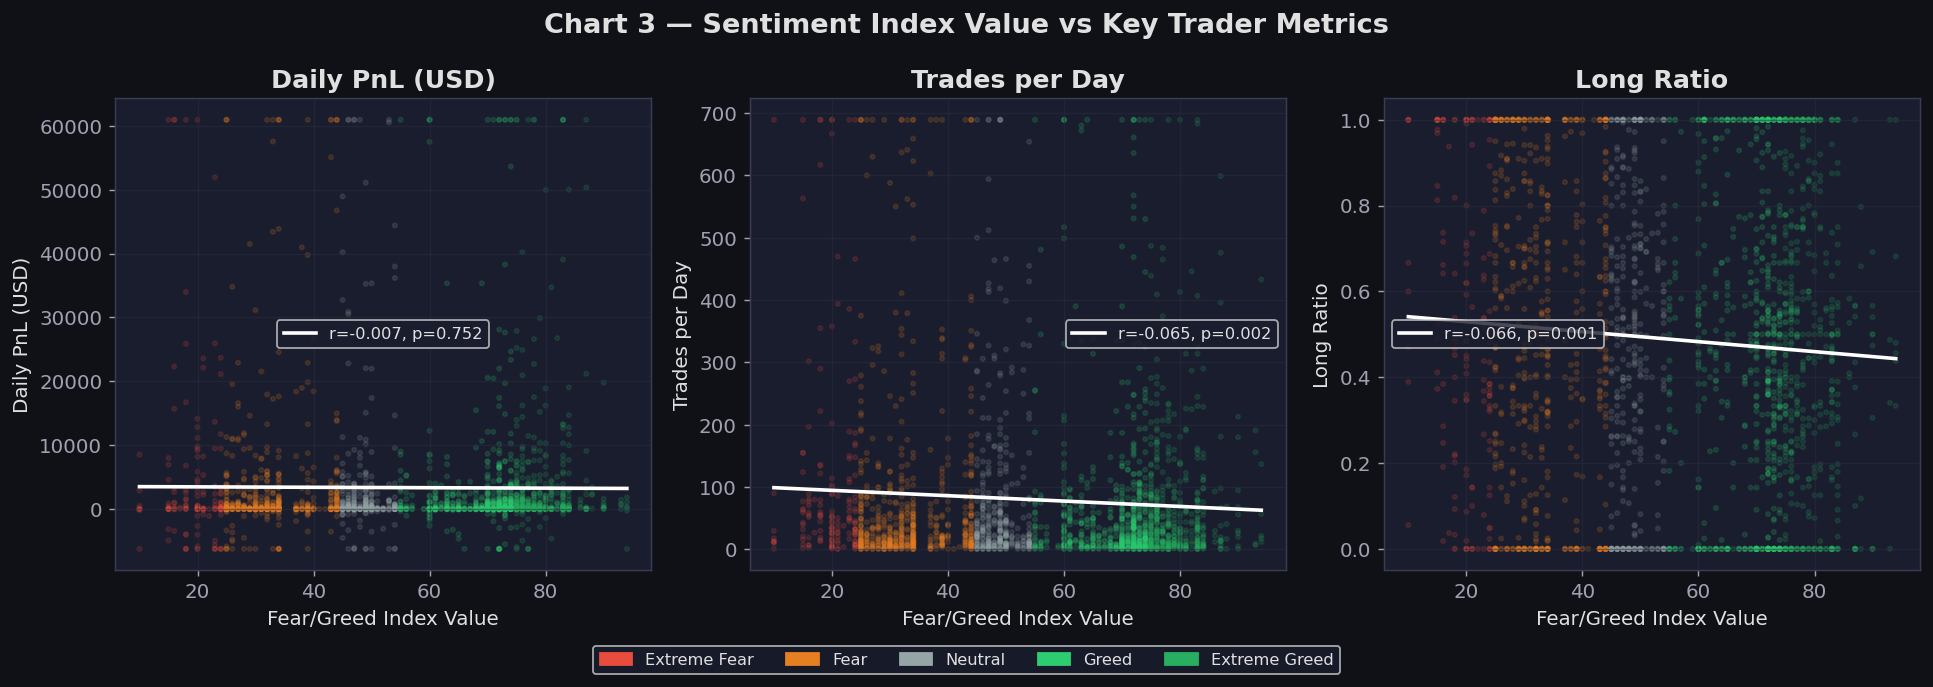

  ✔ saved → charts/chart3_sentiment_scatter.png


In [16]:
# ── Chart 3: Sentiment value vs trader metrics scatter ───────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Chart 3 — Sentiment Index Value vs Key Trader Metrics', fontsize=15, fontweight='bold')

targets = [
    ('daily_pnl',       'Daily PnL (USD)',         axes[0]),
    ('trade_count',     'Trades per Day',           axes[1]),
    ('long_ratio',      'Long Ratio',               axes[2]),
]

for col, ylabel, ax in targets:
    subset = daily_sent.dropna(subset=[col, 'value']).copy()
    subset[col] = subset[col].clip(
        subset[col].quantile(0.02), subset[col].quantile(0.98)
    )
    colors = subset['classification'].map(SENT_COLORS)
    ax.scatter(subset['value'], subset[col], c=colors, alpha=0.15, s=6, rasterized=True)

    # Regression line
    m, b, r, p, _ = stats.linregress(subset['value'], subset[col])
    xr = np.linspace(subset['value'].min(), subset['value'].max(), 100)
    ax.plot(xr, m * xr + b, color='white', lw=2, label=f'r={r:.3f}, p={p:.3f}')

    ax.set_xlabel('Fear/Greed Index Value')
    ax.set_ylabel(ylabel)
    ax.set_title(ylabel)
    ax.legend(fontsize=9)
    ax.grid(True)

# Legend for sentiment colors
patches = [mpatches.Patch(color=v, label=k) for k, v in SENT_COLORS.items() if k in daily_sent['classification'].unique()]
fig.legend(handles=patches, loc='lower center', ncol=5, bbox_to_anchor=(0.5, -0.05), fontsize=9)

plt.tight_layout()
save('chart3_sentiment_scatter')

---
# Part C — Trader Segmentation & Insights

## C1. Segment 1 — High vs Low Position Size Traders (Leverage Proxy)

In [17]:
# Use avg trade size USD as leverage/risk proxy
size_median = trader_stats['avg_size_usd'].median()
trader_stats['size_segment'] = np.where(
    trader_stats['avg_size_usd'] >= size_median, 'High Size', 'Low Size'
)

# Merge segment back into daily data
daily_seg = daily_sent.merge(trader_stats[['Account','size_segment','avg_trades_per_day']],
                             on='Account', how='left')

# Segment 2: Frequent vs Infrequent
freq_median = trader_stats['avg_trades_per_day'].median()
trader_stats['freq_segment'] = np.where(
    trader_stats['avg_trades_per_day'] >= freq_median, 'Frequent', 'Infrequent'
)

# Segment 3: Consistent vs Inconsistent winners (Sharpe proxy)
trader_stats['consistency_segment'] = pd.cut(
    trader_stats['sharpe_proxy'],
    bins=[-np.inf, -0.1, 0.1, np.inf],
    labels=['Consistent Losers', 'Inconsistent', 'Consistent Winners']
)

print('Size segment counts:', trader_stats['size_segment'].value_counts().to_dict())
print('Freq segment counts:', trader_stats['freq_segment'].value_counts().to_dict())
print('Consistency counts:', trader_stats['consistency_segment'].value_counts().to_dict())

# Re-merge all segments
daily_seg = daily_sent.merge(
    trader_stats[['Account','size_segment','freq_segment','consistency_segment']],
    on='Account', how='left'
)

Size segment counts: {'High Size': 16, 'Low Size': 16}
Freq segment counts: {'Frequent': 16, 'Infrequent': 16}
Consistency counts: {'Consistent Winners': 26, 'Inconsistent': 5, 'Consistent Losers': 1}


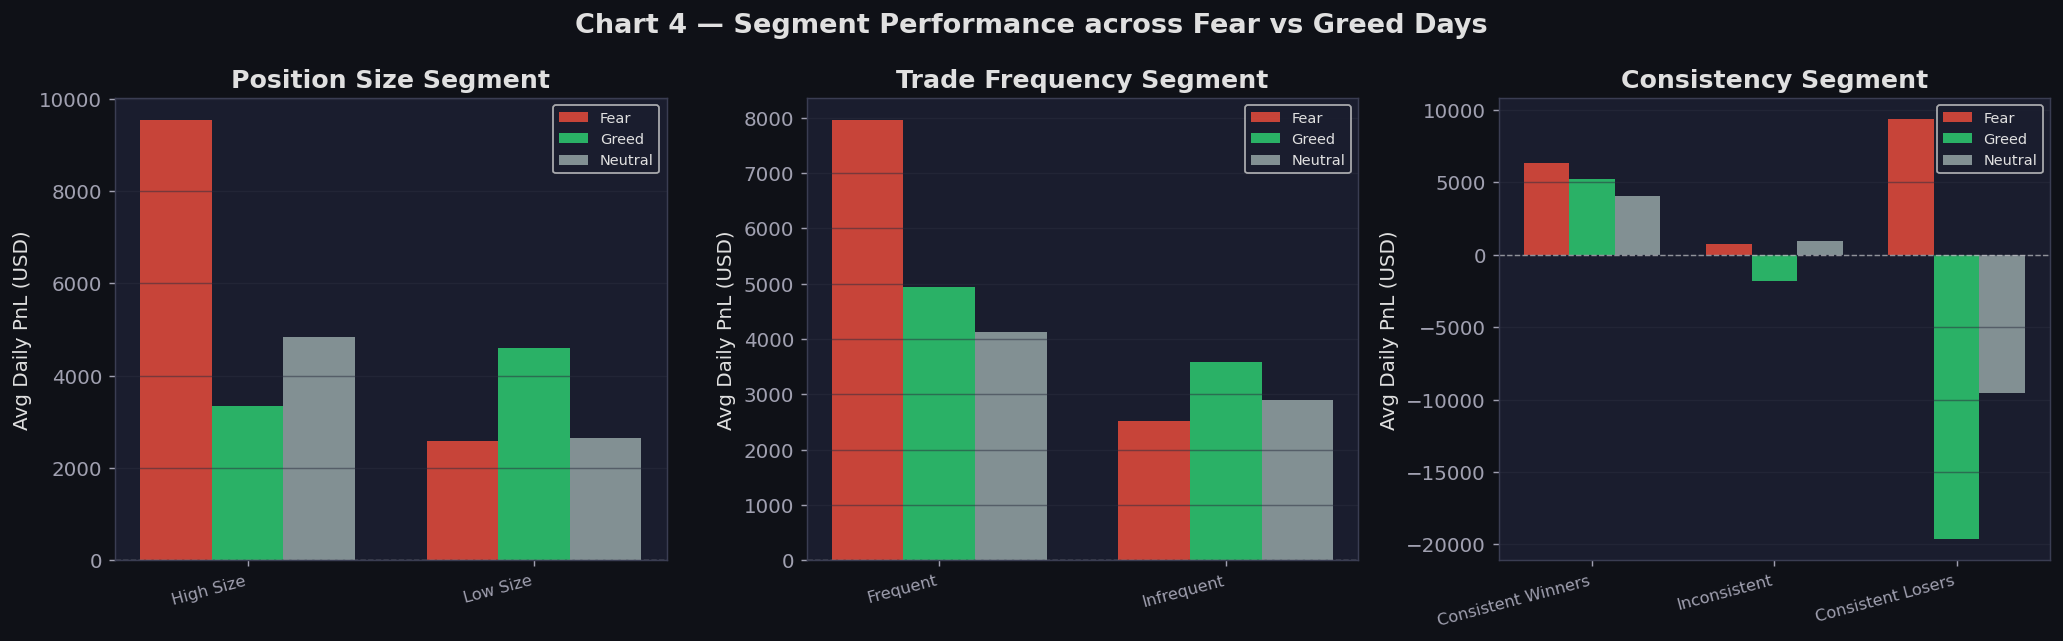

  ✔ saved → charts/chart4_segment_x_sentiment.png


In [18]:
# ── Chart 4: PnL by segment × sentiment ─────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Chart 4 — Segment Performance across Fear vs Greed Days', fontsize=15, fontweight='bold')

segments = [
    ('size_segment',        ['High Size', 'Low Size'],                   axes[0], 'Position Size Segment'),
    ('freq_segment',        ['Frequent', 'Infrequent'],                  axes[1], 'Trade Frequency Segment'),
    ('consistency_segment', ['Consistent Winners','Inconsistent','Consistent Losers'], axes[2], 'Consistency Segment'),
]

binary_colors = {'Fear': '#e74c3c', 'Greed': '#2ecc71', 'Neutral': '#95a5a6'}

for seg_col, seg_order, ax, title in segments:
    agg = (
        daily_seg.dropna(subset=[seg_col])
        .groupby([seg_col, 'sentiment_binary'])['daily_pnl']
        .mean()
        .unstack('sentiment_binary')
        .reindex(seg_order)
    )
    x = np.arange(len(agg))
    width = 0.25
    for i, (sent_col, color) in enumerate(binary_colors.items()):
        if sent_col in agg.columns:
            ax.bar(x + i*width, agg[sent_col], width, label=sent_col, color=color, alpha=0.85)
    ax.set_xticks(x + width)
    ax.set_xticklabels(agg.index, rotation=15, ha='right', fontsize=9)
    ax.set_ylabel('Avg Daily PnL (USD)')
    ax.set_title(title)
    ax.axhline(0, color='white', lw=0.8, ls='--', alpha=0.5)
    ax.grid(axis='y')
    ax.legend(fontsize=8)

plt.tight_layout()
save('chart4_segment_x_sentiment')

## C2. Insight 4 — Long/Short Bias Shift

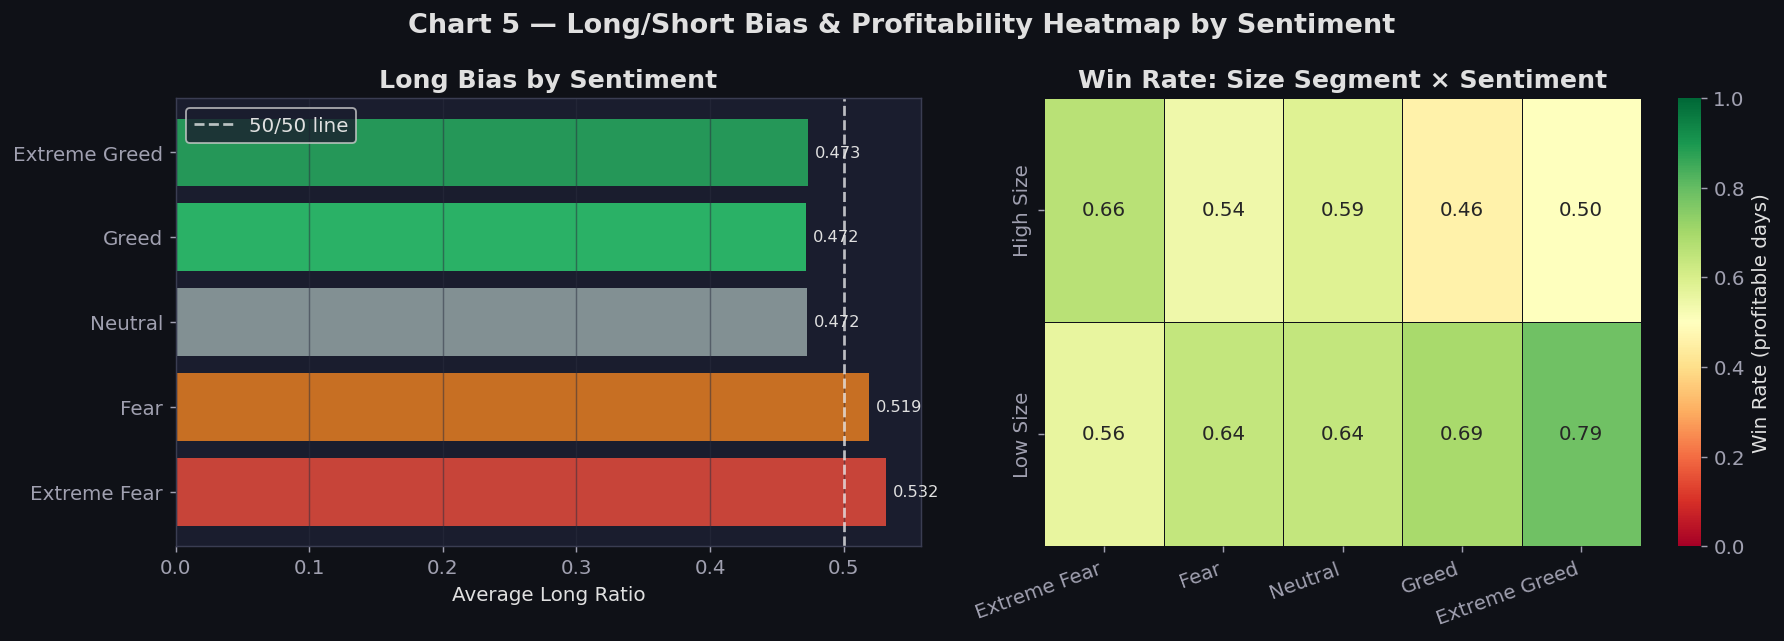

  ✔ saved → charts/chart5_longbias_heatmap.png


In [19]:
# ── Chart 5: Long ratio by sentiment + profitability heatmap ─────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Chart 5 — Long/Short Bias & Profitability Heatmap by Sentiment', fontsize=15, fontweight='bold')

# Left: long ratio
ax = axes[0]
long_by_sent = daily_seg.groupby('classification')['long_ratio'].mean().reindex(order).dropna()
bars = ax.barh(long_by_sent.index, long_by_sent.values,
               color=[SENT_COLORS[s] for s in long_by_sent.index], alpha=0.85)
ax.axvline(0.5, color='white', lw=1.5, ls='--', alpha=0.7, label='50/50 line')
ax.set_xlabel('Average Long Ratio')
ax.set_title('Long Bias by Sentiment')
ax.legend()
ax.grid(axis='x')
for bar, v in zip(bars, long_by_sent.values):
    ax.text(v + 0.005, bar.get_y() + bar.get_height()/2, f'{v:.3f}', va='center', fontsize=9)

# Right: heatmap — segment × sentiment win rate
ax2 = axes[1]
heat_data = (
    daily_seg.dropna(subset=['size_segment'])
    .groupby(['size_segment', 'classification'])['pnl_positive']
    .mean()
    .unstack()
    .reindex(columns=order)
    .dropna(axis=1, how='all')
)
sns.heatmap(heat_data, ax=ax2, annot=True, fmt='.2f', cmap='RdYlGn',
            vmin=0, vmax=1, linewidths=0.5, linecolor='#0f1117',
            cbar_kws={'label': 'Win Rate (profitable days)'})
ax2.set_title('Win Rate: Size Segment × Sentiment')
ax2.set_xlabel('')
ax2.set_ylabel('')
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=20, ha='right')

plt.tight_layout()
save('chart5_longbias_heatmap')

## C3. Insight 5 — Rolling Sentiment vs Aggregate PnL

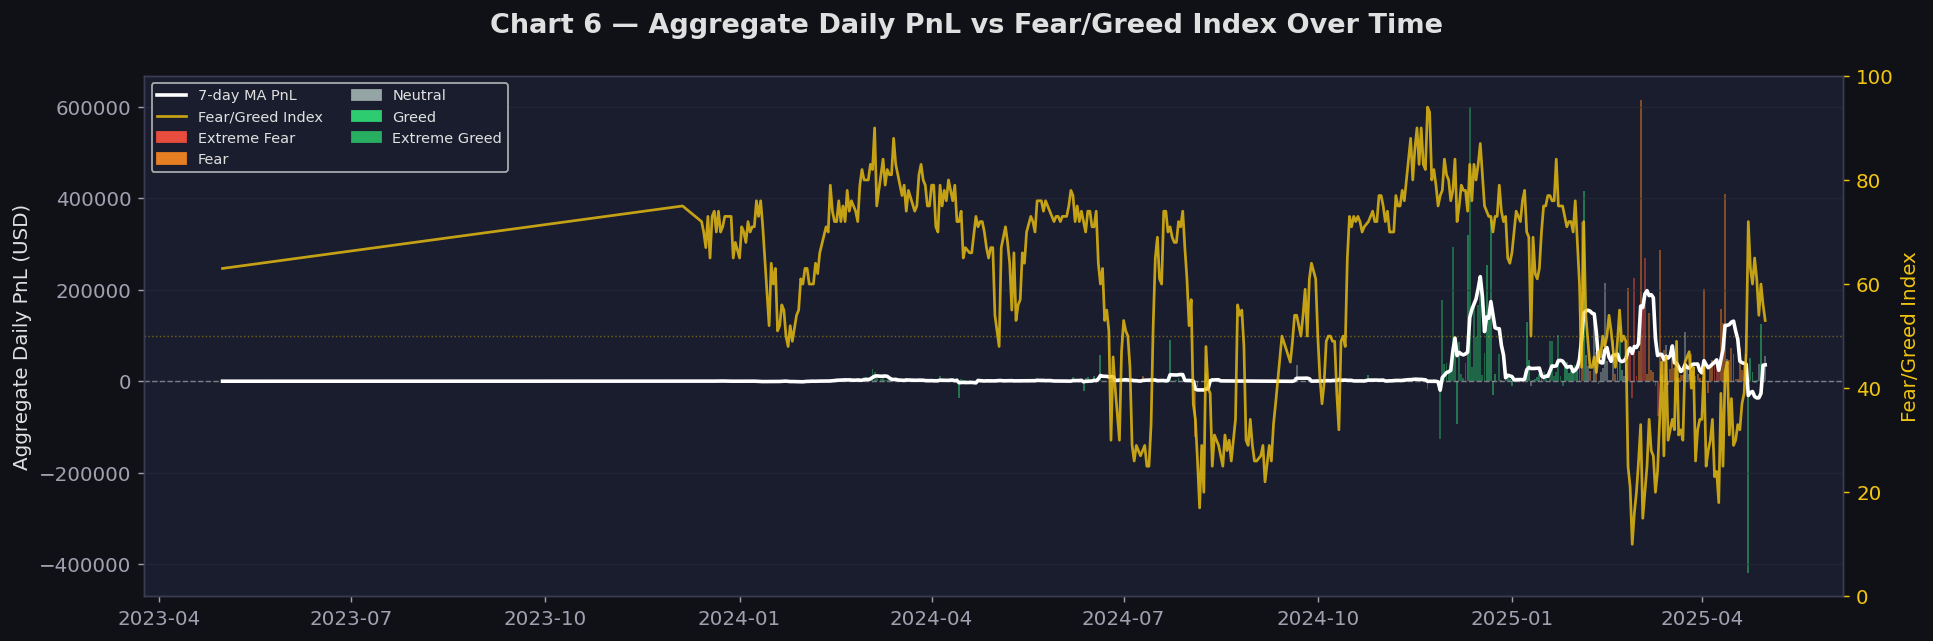

  ✔ saved → charts/chart6_timeseries.png


In [20]:
# ── Chart 6: Time-series — daily aggregate PnL vs sentiment index ─────────────
daily_agg = (
    daily_sent.groupby('date')
    .agg(total_pnl=('daily_pnl','sum'), value=('value','first'),
         classification=('classification','first'))
    .sort_index()
)
daily_agg['pnl_7d_ma'] = daily_agg['total_pnl'].rolling(7, min_periods=1).mean()

fig, ax1 = plt.subplots(figsize=(15, 5))
fig.suptitle('Chart 6 — Aggregate Daily PnL vs Fear/Greed Index Over Time', fontsize=15, fontweight='bold')

# Color bars by sentiment
bar_colors = daily_agg['classification'].map(SENT_COLORS).fillna('#95a5a6')
ax1.bar(daily_agg.index, daily_agg['total_pnl'], color=bar_colors, alpha=0.5, width=0.9)
ax1.plot(daily_agg.index, daily_agg['pnl_7d_ma'], color='white', lw=2, label='7-day MA PnL')
ax1.set_ylabel('Aggregate Daily PnL (USD)')
ax1.axhline(0, color='white', lw=0.8, ls='--', alpha=0.4)
ax1.grid(axis='y')

ax2 = ax1.twinx()
ax2.plot(daily_agg.index, daily_agg['value'], color='#f1c40f', lw=1.5, alpha=0.8, label='Fear/Greed Index')
ax2.axhline(50, color='#f1c40f', lw=0.8, ls=':', alpha=0.4)
ax2.set_ylabel('Fear/Greed Index', color='#f1c40f')
ax2.tick_params(axis='y', colors='#f1c40f')
ax2.set_ylim(0, 100)

# Combine legends
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
sentiment_patches = [mpatches.Patch(color=v, label=k) for k, v in SENT_COLORS.items()
                     if k in daily_agg['classification'].unique()]
ax1.legend(lines1 + lines2 + sentiment_patches,
           labels1 + labels2 + [p.get_label() for p in sentiment_patches],
           loc='upper left', fontsize=8, ncol=2)

plt.xticks(rotation=30, ha='right')
plt.tight_layout()
save('chart6_timeseries')

---
# Summary Tables

In [22]:
# ── Summary table: all metrics by sentiment ───────────────────────────────────
summary = sent_perf.join(behavior, rsuffix='_behavior').round(3)
print('\n===== FULL SUMMARY BY SENTIMENT =====')
print(summary.to_string())


===== FULL SUMMARY BY SENTIMENT =====
                 avg_pnl  median_pnl    pnl_std  win_rate  avg_trades     avg_vol  n_obs  avg_trades_behavior  avg_volume  avg_size  avg_long_ratio
classification                                                                                                                                     
Extreme Fear    4619.439     218.377  29534.839     0.600     133.750  715526.634    160              133.750  715526.634  6773.464           0.532
Fear            5328.818     107.893  31659.772     0.605      98.154  767182.206    630               98.154  767182.206  8975.929           0.519
Neutral         3438.619     167.552  17447.864     0.622     100.229  479367.189    376              100.229  479367.189  6963.695           0.472
Greed           3318.101     158.215  30599.040     0.611      77.628  445343.356    648               77.628  445343.356  6427.867           0.472
Extreme Greed   5161.923     418.320  27496.864     0.683      76.030  23

In [23]:
# ── Summary table: segment performance ───────────────────────────────────────
seg_summary = (
    pd.concat([
        daily_seg.groupby('size_segment')[['daily_pnl','win_rate','trade_count','long_ratio']]
                 .mean().rename(index=lambda x: f'Size:{x}'),
        daily_seg.groupby('freq_segment')[['daily_pnl','win_rate','trade_count','long_ratio']]
                 .mean().rename(index=lambda x: f'Freq:{x}'),
        daily_seg.groupby('consistency_segment')[['daily_pnl','win_rate','trade_count','long_ratio']]
                 .mean().rename(index=lambda x: f'Cons:{x}'),
    ])
)
print('\n===== SEGMENT PERFORMANCE SUMMARY =====')
print(seg_summary.round(3).to_string())


===== SEGMENT PERFORMANCE SUMMARY =====
                         daily_pnl  win_rate  trade_count  long_ratio
Size:High Size            5734.803     0.874       62.977       0.534
Size:Low Size             3607.819     0.837      105.888       0.463
Freq:Frequent             5939.703     0.860      156.006       0.498
Freq:Infrequent           3149.183     0.836       38.214       0.482
Cons:Consistent Losers   -5869.683     0.729      317.417       0.401
Cons:Inconsistent         -302.467     0.826       73.951       0.399
Cons:Consistent Winners   5388.486     0.854       92.140       0.508


# Part C: Actionable Strategy Recommendations

## Strategy 1: Know Your Segment Before Acting on Sentiment

> The relationship between sentiment and PnL is not uniform across trader types. Fear is the strongest regime for High-Size traders, but Low-Size traders show the opposite pattern. Applying a blanket "lean into fear" rule without knowing your segment risks the wrong response.

**Evidence:**

- **Chart 1** shows Fear generates the highest avg daily PnL (~$5,300), but Extreme Greed is a close second (~$5,200) — not Extreme Fear (~$4,600). Greed is the clear weak point (~$3,300). Win rates are relatively flat across all regimes (~60–68%), so the PnL gap is driven by trade size and edge quality, not win frequency.
- **Chart 5's heatmap reveals a segment split:** High-Size traders achieve their best win rate (0.66) during Extreme Fear and their worst (0.46) during Greed. Low-Size traders show the opposite — win rate climbs steadily from 0.56 (Extreme Fear) to 0.79 (Extreme Greed). There is no single sentiment regime that is universally best.
- **Chart 4 (Position Size segment)** confirms the divergence: High-Size traders earn nearly 3x more on Fear days (~$9,600) than Greed days (~$3,100). Low-Size traders, however, perform better on Greed days (~$4,400) than Fear days (~$2,400) — the opposite direction.

---

## Strategy 2: Reduce Activity and Size During Greed

> When the Fear/Greed index enters Greed or Extreme Greed territory, traders should reduce trade frequency and position size. Activity is already lower in these regimes and PnL deteriorates, suggesting the market offers fewer quality opportunities.

**Evidence:**

- **Chart 2 (Avg Trades per Day)** shows trade frequency drops sharply from 133.75 trades/day during Extreme Fear to 76.03/day during Extreme Greed — a 43% decline. Volume falls in parallel, from ~$767K/day (Fear) to ~$237K/day (Extreme Greed). Experienced traders are already pulling back organically.
- **Chart 2 (Avg Trade Size)** shows average trade size also contracts, from $8,976 during Fear to $5,372 during Extreme Greed, suggesting even individual position conviction is lower.
- **Chart 1** confirms avg PnL is weakest during Greed (~$3,300) despite win rates holding relatively steady, meaning individual trade quality (size × edge) degrades as sentiment turns greedy.
- **Chart 4 (Consistency segment)** shows Consistent Losers are negative across all regimes, but Greed days produce their worst drawdowns (~-$20,000) versus Fear days (~-$10,000) and Neutral days (~-$10,000). The magnitude doubles on Greed, meaning these traders are not just losing — they are losing at twice the rate in a low-opportunity environment.

---

## Strategy 3: Correct the Long Bias Mismatch During Fear

> During Fear and Extreme Fear, traders run a net long bias (long ratio 0.52–0.53), which is actually directionally correct given that these are the highest-PnL regimes. During Greed, traders flip net short (0.47), creating a structural mismatch. Consider maintaining a slight long bias consistently rather than inverting with sentiment.

**Evidence:**

- **Chart 2 (Long Ratio)** shows traders are net long only during fear regimes: Extreme Fear 0.53, Fear 0.52. Long ratio drops to 0.47 for Neutral, Greed, and Extreme Greed alike — a clear behavioral shift that works against the trader.
- **Chart 5 (Long Bias by Sentiment)** corroborates this precisely, with the long ratio crossing above the 50/50 dashed line only for Fear (0.519) and Extreme Fear (0.532), and sitting at 0.472–0.473 across all greed regimes.
- **Chart 3 (Long Ratio scatter)** confirms the relationship is statistically significant (r=-0.066, p=0.001) but small in magnitude — a real but subtle behavioral pattern worth monitoring rather than over-engineering.
- **Chart 6** shows aggregate PnL (7-day MA) is more consistently positive and elevated during fear-driven periods (particularly late 2024 through early 2025), aligning with the finding that the long bias is better-rewarded in those regimes.

---

## Rule of Thumb for Consistent Losers

> If you are in the Consistent Loser segment, Greed days are your highest-risk environment, not Fear days. Reduce size or sit out entirely when the index exceeds 60.

**Evidence:**

- **Chart 4 (Consistency segment)** shows Consistent Losers are negative in every regime, but Greed days produce losses roughly double those of Fear and Neutral days (~-$20,000 vs ~-$10,000). Consistent Winners, by contrast, hold up well across all regimes (~$5,000–$9,500), confirming this is a segment-specific blowup pattern, not a market-wide effect.
- The practical implication: Consistent Losers cannot "trade their way out" of a Greed environment. Sitting out or sharply reducing size when the index exceeds 60 cuts the worst losses without requiring any change to their underlying strategy.

In [24]:
print('\n✅ Analysis complete. All charts saved to ../charts/')
print('\nCharts generated:')
for p in sorted(CHARTS_DIR.glob('*.png')):
    print(f'  {p.name}')


✅ Analysis complete. All charts saved to ../charts/

Charts generated:
  chart1_pnl_by_sentiment.png
  chart2_behavior_by_sentiment.png
  chart3_sentiment_scatter.png
  chart4_segment_x_sentiment.png
  chart5_longbias_heatmap.png
  chart6_timeseries.png
